# INAIL 1 Project A dataset audit V1
Run all cells in order. The default path matches the supplied Linux directory. This notebook reads source files without modifying them and writes a timestamped audit folder and a shareable ZIP. Upload the ZIP and the executed notebook for interpretation. No model is trained and no phase-aligned physiological target is assumed valid.

Required packages: `numpy pandas scipy matplotlib openpyxl python-docx nbformat`. Install missing packages in the notebook environment before running. Only the configuration cell needs editing for a different location. The complete run processes one participant file at a time.

Raw EMG units, coordinate units, event indexing and movement–EMG clock alignment remain verification fields. Diagnostic whole-recording RMS values are not lifting-phase outcomes. Data inspection cannot establish novelty or guarantee publication.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import hashlib
import json
import re
import sys
import platform
import traceback
import zipfile
import importlib.metadata
import numpy as np
import pandas as pd
import scipy
from scipy.io import loadmat, whosmat
from scipy.signal import welch
import matplotlib.pyplot as plt
from IPython.display import display

DATA_ROOT = Path.home() / "Downloads/INAIL_1/Dataset1/DATA"
OUTPUT_ROOT = Path.home() / "INAIL_ProjectA_Audit"
EXPECTED_SUBJECTS = 17
MAX_PLOT_SUBJECTS = 3
EXPECTED_EMG = ["RESL", "RESI", "RM", "RLD", "RRAS", "RRAM", "REO", "RIO", "LESL", "LESI", "LM", "LLD", "LRAS", "LRAM", "LEO", "LIO"]

DATA_ROOT = DATA_ROOT.expanduser().resolve()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Edit DATA_ROOT to the existing DATA directory: {DATA_ROOT}")
RUN_DIR = OUTPUT_ROOT.expanduser().resolve() / datetime.now(timezone.utc).strftime("INAIL1_Audit_%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
FIG_DIR = RUN_DIR / "figures"
FIG_DIR.mkdir()
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_rows", 35)
print("Dataset:", DATA_ROOT)
print("Audit output:", RUN_DIR)

Dataset: /home/rafsan/Downloads/INAIL_1/Dataset1/DATA
Audit output: /home/rafsan/INAIL_ProjectA_Audit/INAIL1_Audit_20261113T045702_322247Z


## File inventory and participant identities

In [2]:
def subject_id(value):
    match = re.search(r"(?:^|[^A-Za-z])S0*(\d+)", str(value), flags=re.I)
    return f"S{int(match.group(1)):02d}" if match else None

def ignored(path):
    return "__MACOSX" in path.parts or path.name.startswith("._")

def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

all_files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and not ignored(p))
manifest = pd.DataFrame([{"relative_path": str(p.relative_to(DATA_ROOT)), "extension": p.suffix.lower(), "bytes": p.stat().st_size} for p in all_files])
mat_files = sorted([p for p in all_files if p.suffix.lower() == ".mat" and p.name.lower().endswith("_all_trials.mat")], key=lambda p: (subject_id(p.name) or "", str(p)))
if not mat_files:
    raise FileNotFoundError("No *_all_trials.mat exports found recursively under DATA_ROOT")
file_inventory = pd.DataFrame([{"subject": subject_id(p.name), "file": str(p.relative_to(DATA_ROOT)), "bytes": p.stat().st_size} for p in mat_files])
display(file_inventory)
display(manifest.groupby("extension", dropna=False).agg(files=("bytes", "size"), bytes=("bytes", "sum")))
print("Distinct filename participant IDs:", file_inventory.subject.nunique(), "advertised:", EXPECTED_SUBJECTS)
print("Repeated participant IDs across files:", file_inventory[file_inventory.subject.duplicated(False)].to_dict("records"))

,subject,file,bytes
0,S01,S01/Exported/mat_format/S01_all_trials.mat,29401843
1,S02,S02/Exported/mat_format/S02_all_trials.mat,27572975
2,S03,S03/Exported/mat_format/S03_all_trials.mat,25839487
3,S04,S04/Exported/mat_format/S04_all_trials.mat,29222915
4,S05,S05/Exported/mat_format/S05_all_trials.mat,24613336
5,S06,S06/Exported/mat_format/S06_all_trials.mat,29128217
6,S07,S07/Exported/mat_format/S07_all_trials.mat,25187090
7,S08,S08/Exported/mat_format/S08_all_trials.mat,39785623
8,S09,S09/Exported/mat_format/S09_all_trials.mat,38534845
9,S10,S010/Exported/mat_format/S10_all_trials.mat,31144459


,files,bytes
extension,,
,42,266408
.mat,17,434264806
.tdf,132,263378624
.xlsx,1,9310


Distinct filename participant IDs: 17 advertised: 17
Repeated participant IDs across files: []


## Protocol and participant workbook inspection

In [3]:
protocol_records = []
protocol_tables = []
metadata_records = []
metadata_sheets = []
for p in sorted(DATA_ROOT.parent.glob("*.docx")):
    try:
        from docx import Document
        document = Document(p)
        paragraphs = [x.text for x in document.paragraphs if x.text.strip()]
        protocol_records.append({"file": p.name, "paragraphs": paragraphs})
        for j, table in enumerate(document.tables):
            rows = [[cell.text for cell in row.cells] for row in table.rows]
            protocol_tables.append({"file": p.name, "table": j, "rows": rows})
        print(p.name)
        print("\n".join(paragraphs))
        for item in [t for t in protocol_tables if t["file"] == p.name]:
            display(pd.DataFrame(item["rows"]))
    except Exception as exc:
        protocol_records.append({"file": p.name, "error": str(exc)})
for p in [p for p in all_files if p.suffix.lower() in {".xlsx", ".xls"}]:
    try:
        sheets = pd.read_excel(p, sheet_name=None, header=None)
        for sheet, frame in sheets.items():
            frame = frame.dropna(how="all").dropna(axis=1, how="all")
            metadata_records.append({"file": str(p.relative_to(DATA_ROOT)), "sheet": sheet, "rows": len(frame), "columns": len(frame.columns), "nonempty_cells": int(frame.notna().sum().sum())})
            metadata_sheets.append({"file": str(p.relative_to(DATA_ROOT)), "sheet": sheet, "cells": frame.fillna("").astype(str).values.tolist()})
            print(p.name, sheet, frame.shape)
            display(frame.head(25))
    except Exception as exc:
        metadata_records.append({"file": str(p.relative_to(DATA_ROOT)), "error": str(exc)})
print("Workbook headers, units, and participant linkage require review; no descriptors are silently assigned.")

Subjects_info.xlsx Foglio1 (18, 6)


,0,1,2,3,4,5
0,Participant,Weight (kg),Height (m),BMI (kg/m2),Age (years),Gender
1,S01,68,1.71,23.255019,37,M
2,S02,85,1.84,25.106333,30,M
3,S03,94,1.85,27.465303,42,M
4,S04,92,1.73,30.739417,43,M
5,S05,80,1.86,23.124061,23,M
6,S06,73,1.78,23.04002,27,M
7,S07,82,1.77,26.173833,24,M
8,S08,85,1.95,22.353715,27,M
9,S09,75,1.78,23.671254,41,M


Workbook headers, units, and participant linkage require review; no descriptors are silently assigned.


## Audit functions

In [4]:
def entries(value):
    if isinstance(value, dict):
        return [value]
    if isinstance(value, (list, tuple)):
        return list(value)
    if isinstance(value, np.ndarray):
        return list(value.reshape(-1))
    return []

def numeric(value):
    a = np.asarray(value)
    return a if a.dtype.kind in "biufc" else None

def leaves(value, prefix=""):
    if isinstance(value, dict):
        for key, item in value.items():
            yield from leaves(item, f"{prefix}.{key}" if prefix else key)
    else:
        a = numeric(value)
        if a is not None:
            yield prefix, a

def digest(value):
    h = hashlib.sha256()
    count = 0
    for name, a in sorted(leaves(value)):
        h.update(name.encode())
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(np.ascontiguousarray(a).tobytes())
        count += a.size
    return h.hexdigest() if count else None

def scalar(value):
    try:
        a = np.asarray(value)
        return float(a.reshape(-1)[0]) if a.size == 1 else np.nan
    except Exception:
        return np.nan

def rate(value):
    r = scalar(value)
    return r if np.isfinite(r) and r > 0 else np.nan

def longest_run(mask):
    padded = np.r_[False, np.asarray(mask, dtype=bool).reshape(-1), False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    return int(np.max(edges[1::2] - edges[::2])) if edges.size else 0

def quality(a, fs):
    a = np.asarray(a)
    values = np.real(a).astype(float)
    flat = values.reshape(-1)
    good = flat[np.isfinite(flat)]
    row_bad = ~np.isfinite(values) if values.ndim <= 1 else ~np.isfinite(values).reshape(values.shape[0], -1).all(axis=1)
    result = {"shape": str(tuple(a.shape)), "dtype": str(a.dtype), "samples": int(a.shape[0]) if a.ndim else 1, "elements": int(a.size), "nonfinite_fraction": float(1 - len(good) / a.size) if a.size else np.nan, "longest_missing_samples": longest_run(row_bad), "fs": fs}
    result["duration_s"] = result["samples"] / fs if np.isfinite(fs) and a.size else np.nan
    if good.size:
        result.update(minimum=float(np.min(good)), maximum=float(np.max(good)), mean=float(np.mean(good)), std=float(np.std(good)), rms=float(np.sqrt(np.mean(good ** 2))), abs_p95=float(np.percentile(np.abs(good), 95)), extreme_value_fraction=float(np.mean((good == good.min()) | (good == good.max()))))
        if values.ndim == 1 and len(values) > 1:
            valid = np.isfinite(values[:-1]) & np.isfinite(values[1:])
            result["equal_adjacent_fraction"] = float(np.mean(np.diff(values)[valid] == 0)) if valid.any() else np.nan
    return result

def moving_rms_reference(a, fs):
    a = np.asarray(a, dtype=float).reshape(-1)
    if not np.isfinite(fs) or len(a) < 2 or not np.isfinite(a).all():
        return np.nan
    a = a - np.mean(a)
    width = max(1, min(len(a), int(round(0.25 * fs))))
    rms = np.sqrt(np.maximum(0, np.convolve(a ** 2, np.ones(width) / width, mode="valid")))
    return float(np.percentile(rms, 95))

def describe_schema(value, path="root", depth=0):
    if depth > 6:
        return []
    if isinstance(value, dict):
        rows = [{"path": path, "kind": "dict", "detail": list(value)}]
        for key, item in value.items():
            rows.extend(describe_schema(item, f"{path}.{key}", depth+1))
        return rows
    if isinstance(value, (list, tuple)):
        return [{"path": path, "kind": "list", "detail": len(value)}] + (describe_schema(value[0], path + "[0]", depth+1) if value else [])
    if isinstance(value, np.ndarray):
        return [{"path": path, "kind": "array", "detail": {"shape": list(value.shape), "dtype": str(value.dtype)}}]
    return [{"path": path, "kind": type(value).__name__, "detail": str(value)[:200]}]

GROUPS = {"Kinematic_data": ("data_3D", "fs_3D"), "sEMG": ("data_sEMG", "fs_sEMG"), "Ground_forces_and_moments": ("platform_data", "fs_forces"), "MVC": ("MVC_data", "fs_MVC")}

## Full participant audit
Rates are read from each record. Streams are matched by task name, never by list position. Exact recording hashes omit event annotations deliberately, allowing duplicated arrays with changed events to be detected. Candidate RMS references are diagnostics only: filtering, contraction quality, units and physiological validity remain unresolved.

In [5]:
file_rows, schema_rows, stream_rows, channel_rows, event_rows, errors, reference_rows = [], [], [], [], [], [], []
examples = []
for file_index, path in enumerate(mat_files, 1):
    sid = subject_id(path.name)
    relative = str(path.relative_to(DATA_ROOT))
    print(f"[{file_index}/{len(mat_files)}] {sid}: {relative}", flush=True)
    try:
        inventory = whosmat(path)
        loaded = loadmat(path, simplify_cells=True)
        roots = [(k, v) for k, v in loaded.items() if not k.startswith("__") and isinstance(v, dict) and any(g in v for g in GROUPS)]
        if len(roots) != 1:
            raise ValueError(f"Expected one dataset struct; found {[(k, type(v).__name__) for k,v in loaded.items() if not k.startswith('__')]}")
        root_name, data = roots[0]
        file_rows.append({"subject": sid, "file": relative, "sha256": file_hash(path), "root": root_name, "whosmat": str(inventory), "status": "loaded"})
        schema_rows.append({"subject": sid, "file": relative, "schema": describe_schema(data)})
        for group, (data_key, rate_key) in GROUPS.items():
            for entry_index, entry in enumerate(entries(data.get(group)), 1):
                if not isinstance(entry, dict):
                    errors.append({"subject": sid, "file": relative, "group": group, "entry": entry_index, "error": "Entry is not a dictionary"})
                    continue
                task = str(entry.get("task", f"UNNAMED_{entry_index}"))
                match = re.search(r"LI(\d+)[_ -](\d+)", task, flags=re.I)
                li, repetition = (int(match.group(1)), int(match.group(2))) if match else (None, None)
                fs = rate(entry.get(rate_key))
                values = entry.get(data_key, {})
                base = {"subject": sid, "file": relative, "group": group, "entry": entry_index, "task": task, "task_key": task.lower().removesuffix(".tdf"), "LI": li, "repetition": repetition}
                record = dict(base, fs=fs, recording_sha256=digest(values), task_subject=subject_id(task), exported_fields=" | ".join(entry.keys()))
                lengths = []
                present = []
                for channel, a in leaves(values):
                    stats = quality(a, fs)
                    channel_rows.append(dict(base, channel=channel, **stats))
                    if a.size:
                        lengths.append(stats["samples"])
                        present.append(channel)
                    if group == "MVC":
                        reference_rows.append(dict(base, channel=channel, diagnostic_rms_reference=moving_rms_reference(a, fs)))
                record.update(channels_nonempty=len(present), channels_total=len(list(leaves(values))), sample_count_min=min(lengths) if lengths else np.nan, sample_count_max=max(lengths) if lengths else np.nan, missing_expected_emg=" | ".join(sorted(set(EXPECTED_EMG)-set(present))) if group in {"sEMG", "MVC"} else "")
                stream_rows.append(record)
                if group == "Kinematic_data":
                    for event_name, event_value in entry.get("events", {}).items():
                        value = scalar(event_value)
                        count = min(lengths) if lengths else np.nan
                        event_rows.append(dict(base, event=event_name, value=value, candidate_one_based_time_s=(value-1)/fs if np.isfinite(fs) else np.nan, candidate_one_based_in_bounds=bool(np.isfinite(value) and np.isfinite(count) and 1 <= value <= count), integer_value=bool(np.isfinite(value) and value == int(value))))
        if len(examples) < MAX_PLOT_SUBJECTS:
            examples.append((sid, data))
        del loaded, data
    except Exception as exc:
        file_rows.append({"subject": sid, "file": relative, "status": "failed", "error": str(exc)})
        errors.append({"subject": sid, "file": relative, "error": str(exc), "traceback": traceback.format_exc()})

files_df = pd.DataFrame(file_rows)
streams = pd.DataFrame(stream_rows)
channels = pd.DataFrame(channel_rows)
events = pd.DataFrame(event_rows)
references = pd.DataFrame(reference_rows)
if streams.empty:
    (RUN_DIR / "load_errors.json").write_text(json.dumps(errors, indent=2))
    raise RuntimeError(f"No streams could be audited. Inspect {RUN_DIR / 'load_errors.json'}")
display(files_df)
display(streams.groupby(["subject", "group"]).size().unstack(fill_value=0))
print("Recorded parser errors:", len(errors))

[1/17] S01: S01/Exported/mat_format/S01_all_trials.mat
[2/17] S02: S02/Exported/mat_format/S02_all_trials.mat
[3/17] S03: S03/Exported/mat_format/S03_all_trials.mat
[4/17] S04: S04/Exported/mat_format/S04_all_trials.mat
[5/17] S05: S05/Exported/mat_format/S05_all_trials.mat
[6/17] S06: S06/Exported/mat_format/S06_all_trials.mat
[7/17] S07: S07/Exported/mat_format/S07_all_trials.mat
[8/17] S08: S08/Exported/mat_format/S08_all_trials.mat
[9/17] S09: S09/Exported/mat_format/S09_all_trials.mat
[10/17] S10: S010/Exported/mat_format/S10_all_trials.mat
[11/17] S11: S011/Exported/mat_format/S11_all_trials.mat
[12/17] S12: S012/Exported/mat_format/S12_all_trials.mat
[13/17] S13: S013/Exported/mat_format/S13_all_trials.mat
[14/17] S14: S014/Exported/mat_format/S14_all_trials.mat
[15/17] S15: S015/Exported/mat_format/S15_all_trials.mat
[16/17] S16: S016/Exported/mat_format/S16_all_trials.mat
[17/17] S17: S017/Exported/mat_format/S17_all_trials.mat


,subject,file,sha256,root,whosmat,status
0,S01,S01/Exported/mat_format/S01_all_trials.mat,82215767798f4db8ae95677452ff16d4bea241b1b4d63c...,S01_all_trials,"[('S01_all_trials', (1, 1), 'struct')]",loaded
1,S02,S02/Exported/mat_format/S02_all_trials.mat,a18f34d65b09af88698299b5f5b5dcf332a30117d0a933...,S02_all_trials,"[('S02_all_trials', (1, 1), 'struct')]",loaded
2,S03,S03/Exported/mat_format/S03_all_trials.mat,ec3387b3e8f1408ad62cdd4826360ee503129aed6bbf96...,S03_all_trials,"[('S03_all_trials', (1, 1), 'struct')]",loaded
3,S04,S04/Exported/mat_format/S04_all_trials.mat,4020f524f79fba58a54995c57397228d0debd34d3408b9...,S04_all_trials,"[('S04_all_trials', (1, 1), 'struct')]",loaded
4,S05,S05/Exported/mat_format/S05_all_trials.mat,29086627661898feeb83d0378329835a65b1cfb186d40e...,S05_all_trials,"[('S05_all_trials', (1, 1), 'struct')]",loaded
5,S06,S06/Exported/mat_format/S06_all_trials.mat,b1d3ffbef550ead2e52f417befc463131d7685e66dd3af...,S06_all_trials,"[('S06_all_trials', (1, 1), 'struct')]",loaded
6,S07,S07/Exported/mat_format/S07_all_trials.mat,eb46d93254d2fddd501045a1c0d1585c52fa820fa09715...,S07_all_trials,"[('S07_all_trials', (1, 1), 'struct')]",loaded
7,S08,S08/Exported/mat_format/S08_all_trials.mat,bbddce5a3d5658cb800bd4800ca7f690ead147e2ac1c21...,S08_all_trials,"[('S08_all_trials', (1, 1), 'struct')]",loaded
8,S09,S09/Exported/mat_format/S09_all_trials.mat,a1e8703a901ca3bfd8d41e03f97a7881808b25fe7a5517...,S09_all_trials,"[('S09_all_trials', (1, 1), 'struct')]",loaded
9,S10,S010/Exported/mat_format/S10_all_trials.mat,147ffd2d07488dc5ed2a15839d30af57028b59d9f2fe5a...,S10_all_trials,"[('S10_all_trials', (1, 1), 'struct')]",loaded


group,Ground_forces_and_moments,Kinematic_data,MVC,sEMG
subject,,,,
S01,9,9,2,9
S02,9,9,2,9
S03,9,9,2,9
S04,9,9,2,9
S05,9,9,2,9
S06,9,9,2,9
S07,9,9,2,9
S08,9,9,2,9
S09,9,9,2,9


Recorded parser errors: 0


## Trial completeness and exact duplicate families

In [6]:
lifting = streams[streams.group != "MVC"].copy()
expected_rows = []
for sid in sorted(files_df.subject.dropna().unique()):
    for li in (1,2,3):
        for repetition in (1,2,3):
            selected = lifting[(lifting.subject == sid) & (lifting.LI == li) & (lifting.repetition == repetition)]
            row = {"subject": sid, "LI": li, "repetition": repetition}
            for group in GROUPS:
                if group != "MVC":
                    rows = selected[selected.group == group]
                    row[group + "_entries"] = len(rows)
                    row[group + "_nonempty"] = int((rows.channels_nonempty > 0).sum())
            expected_rows.append(row)
completeness = pd.DataFrame(expected_rows)
duplicate_rows = []
valid_hashes = streams.dropna(subset=["recording_sha256"])
for (group, fingerprint), frame in valid_hashes.groupby(["group", "recording_sha256"]):
    if len(frame) > 1:
        family = group + "_" + fingerprint[:16]
        for item in frame.to_dict("records"):
            duplicate_rows.append(dict(item, duplicate_family=family, family_size=len(frame), crosses_subjects=frame.subject.nunique() > 1))
duplicates = pd.DataFrame(duplicate_rows)
display(completeness)
display(duplicates if not duplicates.empty else pd.DataFrame({"result": ["No exact nonempty recording duplicates found"]}))
unique_counts = lifting.groupby(["subject", "group"]).agg(entries=("task", "size"), distinct_nonempty_recordings=("recording_sha256", "nunique")).reset_index()
display(unique_counts)
print("Duplicate arrays require one representative or a shared split group; source files are retained.")

,subject,LI,repetition,Kinematic_data_entries,Kinematic_data_nonempty,sEMG_entries,sEMG_nonempty,Ground_forces_and_moments_entries,Ground_forces_and_moments_nonempty
0,S01,1,1,1,1,1,1,1,0
1,S01,1,2,1,1,1,1,1,1
2,S01,1,3,1,1,1,1,1,1
3,S01,2,1,1,1,1,1,1,1
4,S01,2,2,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...
148,S17,2,2,1,1,1,1,1,1
149,S17,2,3,1,1,1,1,1,1
150,S17,3,1,0,0,0,0,0,0
151,S17,3,2,0,0,0,0,0,0


,subject,file,group,entry,task,task_key,LI,repetition,fs,recording_sha256,task_subject,exported_fields,channels_nonempty,channels_total,sample_count_min,sample_count_max,missing_expected_emg,duplicate_family,family_size,crosses_subjects
0,S09,S09/Exported/mat_format/S09_all_trials.mat,Ground_forces_and_moments,8,S09_Lift_LI3_2.TDF,s09_lift_li3_2,3.0,2.0,680.0,585a5de21fa78f66d8607532a65c0fc70543df94f568de...,S09,task | fs_forces | platform_data,8,8,5399.0,5399.0,,Ground_forces_and_moments_585a5de21fa78f66,2,False
1,S09,S09/Exported/mat_format/S09_all_trials.mat,Ground_forces_and_moments,9,S09_Lift_LI3_3.TDF,s09_lift_li3_3,3.0,3.0,680.0,585a5de21fa78f66d8607532a65c0fc70543df94f568de...,S09,task | fs_forces | platform_data,8,8,5399.0,5399.0,,Ground_forces_and_moments_585a5de21fa78f66,2,False
2,S14,S014/Exported/mat_format/S14_all_trials.mat,Ground_forces_and_moments,4,S14_Lift_LI2_1.TDF,s14_lift_li2_1,2.0,1.0,680.0,7b767e371d64d76c6e797b5dc127ea325c519702b6edca...,S14,task | fs_forces | platform_data,8,8,4675.0,4675.0,,Ground_forces_and_moments_7b767e371d64d76c,2,False
3,S14,S014/Exported/mat_format/S14_all_trials.mat,Ground_forces_and_moments,5,S14_Lift_LI2_2.TDF,s14_lift_li2_2,2.0,2.0,680.0,7b767e371d64d76c6e797b5dc127ea325c519702b6edca...,S14,task | fs_forces | platform_data,8,8,4675.0,4675.0,,Ground_forces_and_moments_7b767e371d64d76c,2,False
4,S12,S012/Exported/mat_format/S12_all_trials.mat,Ground_forces_and_moments,4,S12_Lift_LI2_1.TDF,s12_lift_li2_1,2.0,1.0,680.0,90b070d1273fc026d1c41e10a3b24fb5e22473f6572651...,S12,task | fs_forces | platform_data,8,8,3369.0,3369.0,,Ground_forces_and_moments_90b070d1273fc026,2,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33,S04,S04/Exported/mat_format/S04_all_trials.mat,sEMG,9,S04_Lift_LI3_3.TDF,s04_lift_li3_3,3.0,3.0,1000.0,af029a5c1fd2917fc208c0ad2e0217a97bcb781c7f075c...,S04,task | fs_sEMG | data_sEMG,16,16,18006.0,18006.0,,sEMG_af029a5c1fd2917f,2,False
34,S05,S05/Exported/mat_format/S05_all_trials.mat,sEMG,8,S05_Lift_LI3_2.TDF,s05_lift_li3_2,3.0,2.0,1000.0,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,S05,task | fs_sEMG | data_sEMG,16,16,8782.0,8782.0,,sEMG_cba12c991fca50d7,2,False
35,S05,S05/Exported/mat_format/S05_all_trials.mat,sEMG,9,S05_Lift_LI3_3.TDF,s05_lift_li3_3,3.0,3.0,1000.0,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,S05,task | fs_sEMG | data_sEMG,16,16,8782.0,8782.0,,sEMG_cba12c991fca50d7,2,False
36,S14,S014/Exported/mat_format/S14_all_trials.mat,sEMG,4,S14_Lift_LI2_1.TDF,s14_lift_li2_1,2.0,1.0,1000.0,f215cfff03f85e23d62505206bebbc6f73105da92514a5...,S14,task | fs_sEMG | data_sEMG,16,16,8784.0,8784.0,,sEMG_f215cfff03f85e23,2,False


,subject,group,entries,distinct_nonempty_recordings
0,S01,Ground_forces_and_moments,9,7
1,S01,Kinematic_data,9,8
2,S01,sEMG,9,8
3,S02,Ground_forces_and_moments,9,9
4,S02,Kinematic_data,9,9
...,...,...,...,...
46,S16,Kinematic_data,6,6
47,S16,sEMG,6,6
48,S17,Ground_forces_and_moments,6,6
49,S17,Kinematic_data,6,6


Duplicate arrays require one representative or a shared split group; source files are retained.


## Timing and event evidence
Event times below assume one-based movement-frame indices solely for inspection. Different stream durations do not identify the correct offset, and equal durations would not prove synchronization. No EMG segment is extracted using these event indices.

In [7]:
timing_rows = []
for (sid, task), frame in lifting.groupby(["subject", "task_key"]):
    row = {"subject": sid, "task_key": task}
    for group in ("Kinematic_data", "sEMG", "Ground_forces_and_moments"):
        part = frame[frame.group == group]
        row[group + "_matches"] = len(part)
        if len(part) == 1:
            rec = part.iloc[0]
            row[group + "_fs"] = rec.fs
            row[group + "_duration_min_s"] = rec.sample_count_min / rec.fs if np.isfinite(rec.fs) else np.nan
            row[group + "_duration_max_s"] = rec.sample_count_max / rec.fs if np.isfinite(rec.fs) else np.nan
    motion_duration = row.get("Kinematic_data_duration_min_s", np.nan)
    emg_duration = row.get("sEMG_duration_min_s", np.nan)
    row["emg_minus_motion_duration_s"] = emg_duration - motion_duration
    row["alignment_status"] = "unverified_clock_offset_and_event_semantics"
    ev = events[(events.subject == sid) & (events.task_key == task)] if not events.empty else pd.DataFrame()
    ev_map = dict(zip(ev.event, ev.value)) if not ev.empty else {}
    start, stop, lowering = (ev_map.get(k, np.nan) for k in ("start", "stop", "stop_lowering"))
    row["events_ordered"] = bool(np.isfinite([start,stop,lowering]).all() and start < stop < lowering)
    row["events_in_candidate_bounds"] = bool(len(ev) >= 3 and ev.candidate_one_based_in_bounds.all()) if not ev.empty else False
    row["candidate_lifting_seconds"] = (stop-start)/row.get("Kinematic_data_fs", np.nan)
    timing_rows.append(row)
timing = pd.DataFrame(timing_rows)
display(timing)
display(events)
print("Observed duration mismatch summary:")
display(timing[["emg_minus_motion_duration_s", "candidate_lifting_seconds"]].describe())

,subject,task_key,Kinematic_data_matches,Kinematic_data_fs,Kinematic_data_duration_min_s,Kinematic_data_duration_max_s,sEMG_matches,sEMG_fs,sEMG_duration_min_s,sEMG_duration_max_s,Ground_forces_and_moments_matches,Ground_forces_and_moments_fs,Ground_forces_and_moments_duration_min_s,Ground_forces_and_moments_duration_max_s,emg_minus_motion_duration_s,alignment_status,events_ordered,events_in_candidate_bounds,candidate_lifting_seconds
0,S01,s01_lift_li1_1,1,340.0,9.491176,9.491176,1,1000.0,11.482,11.482,1,680.0,NaN,NaN,1.990824,unverified_clock_offset_and_event_semantics,True,True,1.832353
1,S01,s01_lift_li1_2,1,340.0,7.270588,7.270588,1,1000.0,8.921,8.921,1,680.0,7.216176,7.216176,1.650412,unverified_clock_offset_and_event_semantics,True,True,1.102941
2,S01,s01_lift_li1_3,1,340.0,7.270588,7.270588,1,1000.0,8.921,8.921,1,680.0,7.216176,7.216176,1.650412,unverified_clock_offset_and_event_semantics,True,True,1.088235
3,S01,s01_lift_li2_1,1,340.0,4.426471,4.426471,1,1000.0,6.449,6.449,1,680.0,4.375000,4.375000,2.022529,unverified_clock_offset_and_event_semantics,True,True,0.747059
4,S01,s01_lift_li2_2,1,340.0,5.629412,5.629412,1,1000.0,7.428,7.428,1,680.0,5.598529,5.598529,1.798588,unverified_clock_offset_and_event_semantics,True,True,0.829412
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,S17,s17_lift_li1_2,1,340.0,6.297059,6.297059,1,1000.0,7.930,7.930,1,680.0,6.276471,6.276471,1.632941,unverified_clock_offset_and_event_semantics,True,True,1.311765
128,S17,s17_lift_li1_3,1,340.0,7.082353,7.082353,1,1000.0,8.824,8.824,1,680.0,6.994118,6.994118,1.741647,unverified_clock_offset_and_event_semantics,True,True,1.247059
129,S17,s17_lift_li2_1,1,340.0,9.285294,9.285294,1,1000.0,10.896,10.896,1,680.0,9.273529,9.273529,1.610706,unverified_clock_offset_and_event_semantics,True,True,1.100000
130,S17,s17_lift_li2_2,1,340.0,8.547059,8.547059,1,1000.0,10.589,10.589,1,680.0,8.454412,8.454412,2.041941,unverified_clock_offset_and_event_semantics,True,True,1.723529


,subject,file,group,entry,task,task_key,LI,repetition,event,value,candidate_one_based_time_s,candidate_one_based_in_bounds,integer_value
0,S01,S01/Exported/mat_format/S01_all_trials.mat,Kinematic_data,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1,1,start,1576.0,4.632353,True,True
1,S01,S01/Exported/mat_format/S01_all_trials.mat,Kinematic_data,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1,1,stop,2199.0,6.464706,True,True
2,S01,S01/Exported/mat_format/S01_all_trials.mat,Kinematic_data,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1,1,stop_lowering,2768.0,8.138235,True,True
3,S01,S01/Exported/mat_format/S01_all_trials.mat,Kinematic_data,2,S01_Lift_LI1_2.TDF,s01_lift_li1_2,1,2,start,900.0,2.644118,True,True
4,S01,S01/Exported/mat_format/S01_all_trials.mat,Kinematic_data,2,S01_Lift_LI1_2.TDF,s01_lift_li1_2,1,2,stop,1275.0,3.747059,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,S17,S017/Exported/mat_format/S17_all_trials.mat,Kinematic_data,5,S17_Lift_LI2_2.TDF,s17_lift_li2_2,2,2,stop,1594.0,4.685294,True,True
392,S17,S017/Exported/mat_format/S17_all_trials.mat,Kinematic_data,5,S17_Lift_LI2_2.TDF,s17_lift_li2_2,2,2,stop_lowering,2065.0,6.070588,True,True
393,S17,S017/Exported/mat_format/S17_all_trials.mat,Kinematic_data,6,S17_Lift_LI2_3.TDF,s17_lift_li2_3,2,3,start,1055.0,3.100000,True,True
394,S17,S017/Exported/mat_format/S17_all_trials.mat,Kinematic_data,6,S17_Lift_LI2_3.TDF,s17_lift_li2_3,2,3,stop,1583.0,4.652941,True,True


Observed duration mismatch summary:


,emg_minus_motion_duration_s,candidate_lifting_seconds
count,132.000000,132.000000
mean,1.942480,1.394764
std,1.131113,0.340360
min,1.407941,0.747059
25%,1.693353,1.146324
50%,1.826882,1.372059
75%,1.917265,1.535294
max,10.935412,2.664706


## Signal quality and MVC availability

In [8]:
display(channels.groupby("group").agg(arrays=("channel", "size"), empty_arrays=("elements", lambda x: int((x==0).sum())), nonfinite_arrays=("nonfinite_fraction", lambda x: int((x>0).sum())), constant_arrays=("std", lambda x: int((x==0).sum()))))
signal_flags = channels[(channels.elements == 0) | (channels.nonfinite_fraction > 0) | (channels["std"] == 0)].copy()
display(signal_flags)
display(streams[(streams.group.isin(["sEMG", "MVC"])) & streams.missing_expected_emg.ne("")])
if not references.empty:
    mvc_summary = references.groupby(["subject", "channel"]).agg(reference_entries=("task", "size"), positive_diagnostic_references=("diagnostic_rms_reference", lambda x: int((x>0).sum())), reference_min=("diagnostic_rms_reference", "min"), reference_max=("diagnostic_rms_reference", "max")).reset_index()
    mvc_summary["repeat_max_min_ratio"] = mvc_summary.reference_max / mvc_summary.reference_min.replace(0, np.nan)
else:
    mvc_summary = pd.DataFrame(columns=["subject", "channel", "reference_entries", "positive_diagnostic_references"])
display(mvc_summary)
print("RMS reference uses demeaned unfiltered signals, a 250 ms window and a 95th percentile. It is a diagnostic candidate, not approved MVC normalization.")

,arrays,empty_arrays,nonfinite_arrays,constant_arrays
group,,,,
Ground_forces_and_moments,1056,40,1,0
Kinematic_data,4884,0,0,0
MVC,544,0,0,0
sEMG,2112,0,0,0


,subject,file,group,entry,task,task_key,LI,repetition,channel,shape,dtype,samples,elements,nonfinite_fraction,longest_missing_samples,fs,duration_s,minimum,maximum,mean,std,rms,abs_p95,extreme_value_fraction,equal_adjacent_fraction
477,S01,S01/Exported/mat_format/S01_all_trials.mat,Ground_forces_and_moments,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1.0,1.0,F_l,"(0,)",uint8,0,0,NaN,0,680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
478,S01,S01/Exported/mat_format/S01_all_trials.mat,Ground_forces_and_moments,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1.0,1.0,F_r,"(0,)",uint8,0,0,NaN,0,680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
479,S01,S01/Exported/mat_format/S01_all_trials.mat,Ground_forces_and_moments,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1.0,1.0,CoP_r,"(0,)",uint8,0,0,NaN,0,680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
480,S01,S01/Exported/mat_format/S01_all_trials.mat,Ground_forces_and_moments,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1.0,1.0,CoP_l,"(0,)",uint8,0,0,NaN,0,680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
481,S01,S01/Exported/mat_format/S01_all_trials.mat,Ground_forces_and_moments,1,S01_Lift_LI1_1.TDF,s01_lift_li1_1,1.0,1.0,M_r,"(0,)",uint8,0,0,NaN,0,680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2869,S05,S05/Exported/mat_format/S05_all_trials.mat,Ground_forces_and_moments,9,S05_Lift_LI3_3.TDF,s05_lift_li3_3,3.0,3.0,M_r,"(0,)",uint8,0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2870,S05,S05/Exported/mat_format/S05_all_trials.mat,Ground_forces_and_moments,9,S05_Lift_LI3_3.TDF,s05_lift_li3_3,3.0,3.0,M_l,"(0,)",uint8,0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2871,S05,S05/Exported/mat_format/S05_all_trials.mat,Ground_forces_and_moments,9,S05_Lift_LI3_3.TDF,s05_lift_li3_3,3.0,3.0,Cop_ris,"(0,)",uint8,0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2872,S05,S05/Exported/mat_format/S05_all_trials.mat,Ground_forces_and_moments,9,S05_Lift_LI3_3.TDF,s05_lift_li3_3,3.0,3.0,F_ris,"(0,)",uint8,0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,subject,file,group,entry,task,task_key,LI,repetition,fs,recording_sha256,task_subject,exported_fields,channels_nonempty,channels_total,sample_count_min,sample_count_max,missing_expected_emg


,subject,channel,reference_entries,positive_diagnostic_references,reference_min,reference_max,repeat_max_min_ratio
0,S01,LEO,2,2,231.511730,237.384605,1.025368
1,S01,LESI,2,2,367.902397,414.025473,1.125368
2,S01,LESL,2,2,304.242493,375.807769,1.235224
3,S01,LIO,2,2,1465.237318,1783.456023,1.217179
4,S01,LLD,2,2,150.468881,159.776620,1.061858
...,...,...,...,...,...,...,...
267,S17,RIO,2,2,54.413225,58.663517,1.078111
268,S17,RLD,2,2,116.343975,162.670481,1.398186
269,S17,RM,2,2,69.609161,88.472237,1.270986
270,S17,RRAM,2,2,120.068187,134.651601,1.121459


RMS reference uses demeaned unfiltered signals, a 250 ms window and a 95th percentile. It is a diagnostic candidate, not approved MVC normalization.


## Diagnostic figures
Movement and EMG use their own elapsed-time axes. Plots do not imply synchronization. Highlighted movement events are candidate interpretations. EMG spectra describe the exported recordings, with amplitude units unverified.

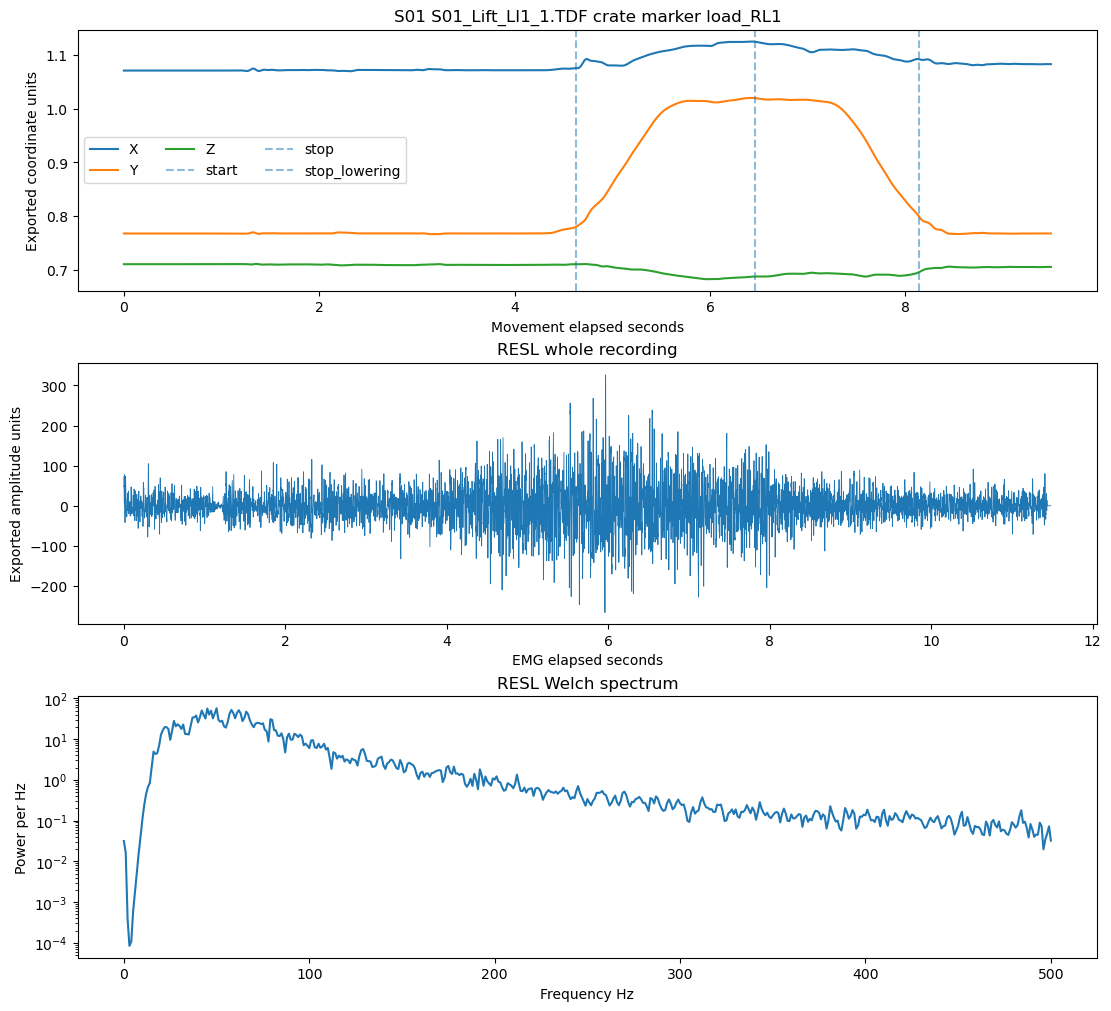

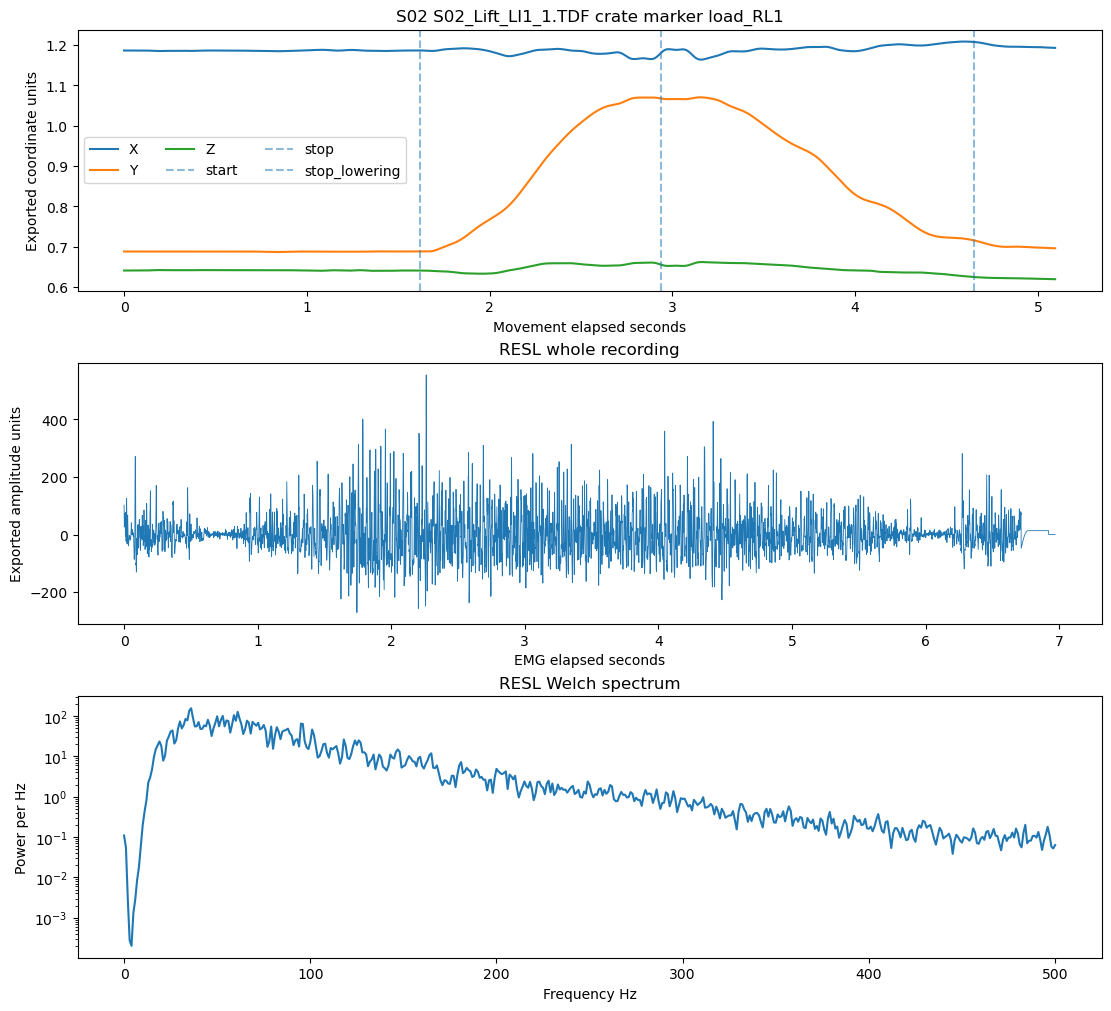

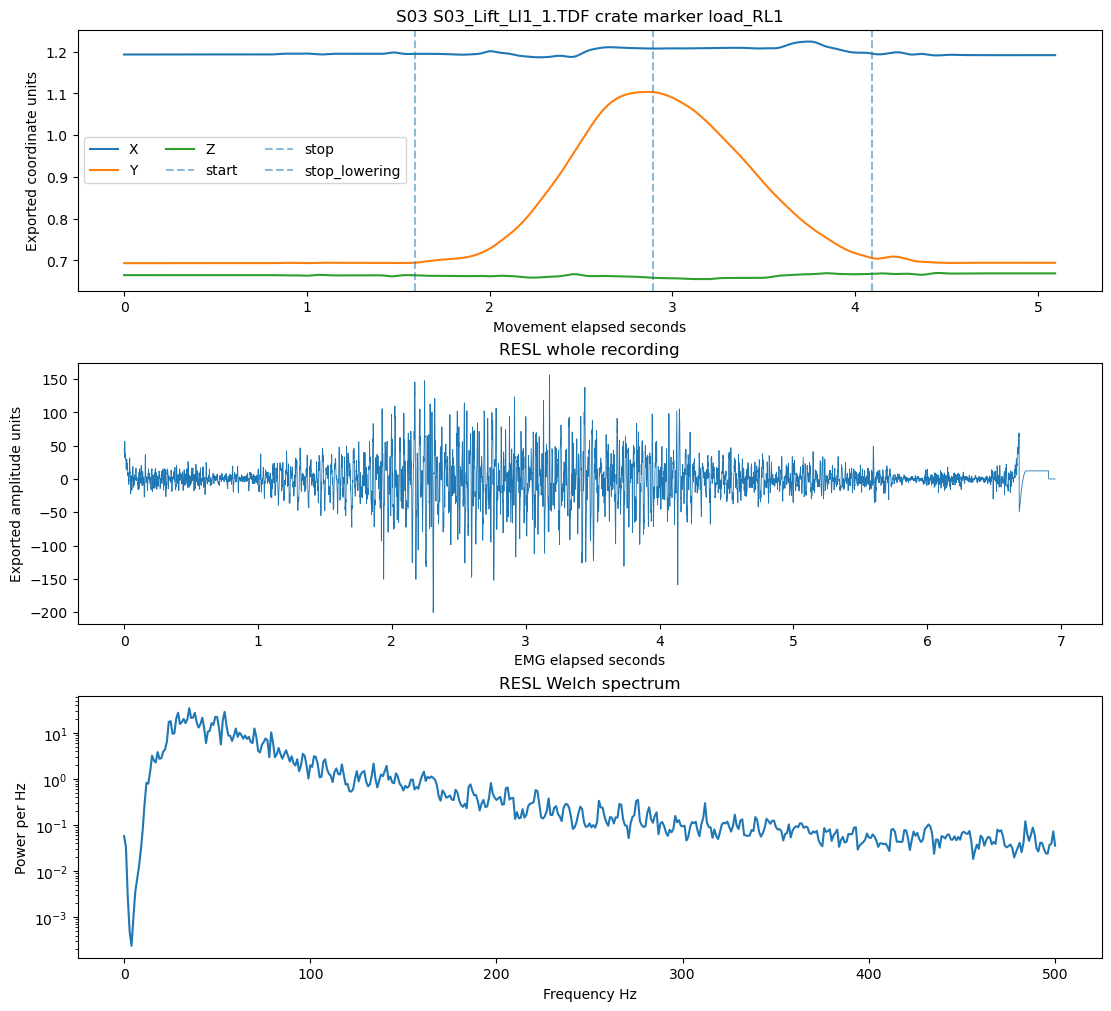

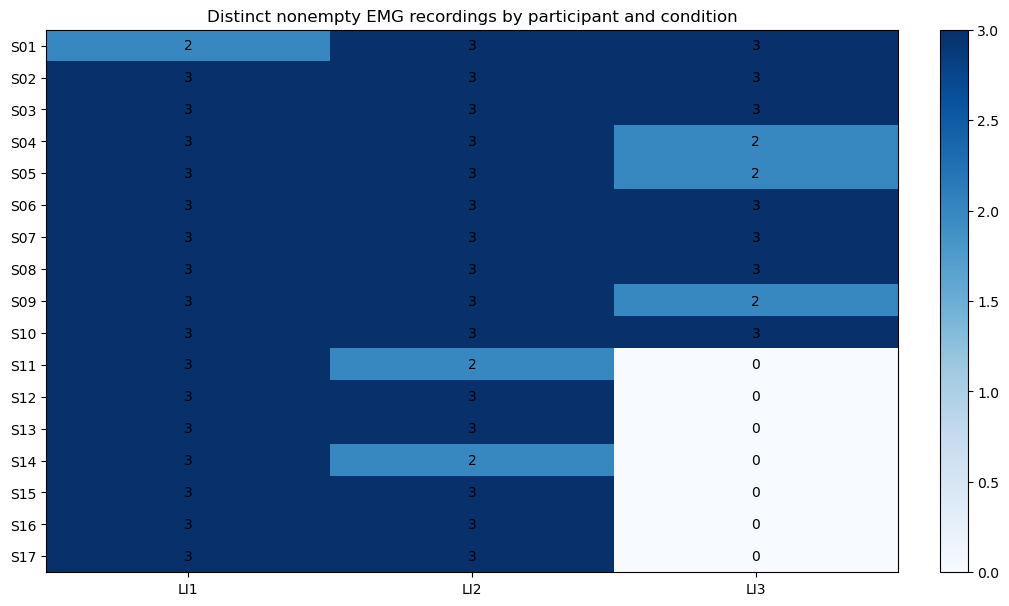

In [9]:
figure_files = []
for sid, data in examples:
    motion_entries = entries(data.get("Kinematic_data"))
    emg_entries = {str(e.get("task", "")).lower(): e for e in entries(data.get("sEMG")) if isinstance(e, dict)}
    if not motion_entries:
        continue
    motion = motion_entries[0]
    emg = emg_entries.get(str(motion.get("task", "")).lower())
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), constrained_layout=True)
    fs = rate(motion.get("fs_3D"))
    markers = motion.get("data_3D", {})
    marker = next((k for k in markers if k.lower().startswith("load")), None)
    if marker and np.isfinite(fs):
        a = np.asarray(markers[marker])
        if a.ndim == 2 and a.shape[1] >= 3:
            for j, label in enumerate(["X", "Y", "Z"]):
                axes[0].plot(np.arange(len(a))/fs, a[:,j], label=label)
            for key, value in motion.get("events", {}).items():
                t = (scalar(value)-1)/fs
                if np.isfinite(t):
                    axes[0].axvline(t, linestyle="--", alpha=0.5, label=key)
            axes[0].legend(ncol=3)
    axes[0].set(title=f"{sid} {motion.get('task')} crate marker {marker}", xlabel="Movement elapsed seconds", ylabel="Exported coordinate units")
    if emg:
        fs_e = rate(emg.get("fs_sEMG"))
        signal = emg.get("data_sEMG", {}).get("RESL")
        if signal is not None and np.isfinite(fs_e):
            a = np.asarray(signal, dtype=float).reshape(-1)
            axes[1].plot(np.arange(len(a))/fs_e, a, linewidth=0.6)
            if len(a)>8 and np.isfinite(a).all():
                freq, power = welch(a, fs=fs_e, nperseg=min(len(a), int(fs_e)))
                axes[2].semilogy(freq, np.maximum(power, np.finfo(float).tiny))
    axes[1].set(title="RESL whole recording", xlabel="EMG elapsed seconds", ylabel="Exported amplitude units")
    axes[2].set(title="RESL Welch spectrum", xlabel="Frequency Hz", ylabel="Power per Hz")
    output = FIG_DIR / f"{sid}_first_trial.png"
    fig.savefig(output, dpi=130)
    figure_files.append(str(output.relative_to(RUN_DIR)))
    plt.show()
    plt.close(fig)
fig, ax = plt.subplots(figsize=(10, max(3, 0.35*files_df.subject.nunique())), constrained_layout=True)
counts = lifting[lifting.group == "sEMG"].pivot_table(index="subject", columns="LI", values="recording_sha256", aggfunc="nunique", fill_value=0).reindex(columns=[1,2,3], fill_value=0)
image = ax.imshow(counts.values, vmin=0, vmax=3, aspect="auto", cmap="Blues")
ax.set_xticks(range(3), ["LI1", "LI2", "LI3"])
ax.set_yticks(range(len(counts)), counts.index)
for i in range(len(counts)):
    for j in range(3):
        ax.text(j, i, str(counts.iloc[i,j]), ha="center", va="center")
ax.set_title("Distinct nonempty EMG recordings by participant and condition")
fig.colorbar(image, ax=ax)
output = FIG_DIR / "condition_coverage.png"
fig.savefig(output, dpi=130)
figure_files.append(str(output.relative_to(RUN_DIR)))
plt.show()
plt.close(fig)

## Project A readiness and INAIL 2 decision
The audit can establish technical availability and document obstacles. It cannot establish physiological target validity, statistical power or predictive added value automatically. INAIL 2 is an extension candidate for compatible-protocol evaluation; it does not repair unresolved INAIL 1 timing or turn team lifting into the same task.

In [10]:
loaded_subjects = files_df.loc[files_df.status.eq("loaded"), "subject"].nunique()
paired_candidates = int(((timing.Kinematic_data_matches == 1) & (timing.sEMG_matches == 1) & timing.Kinematic_data_duration_min_s.gt(0) & timing.sEMG_duration_min_s.gt(0)).sum())
subject_mismatch = streams[streams.task_subject.notna() & streams.subject.ne(streams.task_subject) & streams.group.ne("MVC")]
checks = pd.DataFrame([
    {"check": "Advertised cohort", "observed": f"{loaded_subjects}/{EXPECTED_SUBJECTS} participant IDs loaded", "status": "observed_complete_count" if loaded_subjects == EXPECTED_SUBJECTS else "partial_or_different_count"},
    {"check": "Movement and EMG task matches", "observed": str(paired_candidates), "status": "candidates_pending_timing_and_QC"},
    {"check": "Exact duplicate rows", "observed": str(len(duplicates)), "status": "review_and_group_or_retain_one" if len(duplicates) else "none_detected"},
    {"check": "Task participant mismatch", "observed": str(len(subject_mismatch)), "status": "review" if len(subject_mismatch) else "none_detected"},
    {"check": "Signal flag rows", "observed": str(len(signal_flags)), "status": "channel_specific_review"},
    {"check": "Event semantics and clock alignment", "observed": "No verified common time origin supplied", "status": "unresolved"},
    {"check": "MVC physiological validity", "observed": "Availability and diagnostic RMS only", "status": "unresolved"},
    {"check": "Participant descriptors", "observed": f"{len(metadata_sheets)} workbook sheets extracted", "status": "verify_headers_units_and_ID_mapping"},
    {"check": "Within-condition added predictive value", "observed": "Requires later worker-separated modelling", "status": "not_tested"}
])
decision = {
    "INAIL1_start": "Proceed with audit resolution and target construction when movement, EMG, MVC and timing are verified; do not start phase-supervised training from this audit alone.",
    "INAIL2_for_initial_Project_A": "Not an automatic requirement. Decide after valid INAIL1 targets, worker coverage and within-condition variability are established.",
    "INAIL2_when_useful": "Compatible independent-protocol validation, broader lifting conditions, or a later journal extension; verify muscles, normalization, task semantics and participant independence first.",
    "INAIL2_when_not_a_fix": "It cannot by itself resolve INAIL1 timing, invalid MVC references, duplicates or a task-confounded model.",
    "decision_limit": "No binary publication or sufficiency verdict can be inferred solely from participant counts or file readability.",
    "next_analysis": ["Resolve event indexing and stream offsets using acquisition metadata or source export", "Review channel units, MVC contractions and recording exclusions", "Map Subjects_info columns to participant pseudonyms", "Construct valid lifting-phase outcomes", "Use worker-grouped splits and duplicate-family controls", "Compare full task/descriptor baseline with movement models within lifting conditions"]
}
display(checks)
print(json.dumps(decision, indent=2))

,check,observed,status
0,Advertised cohort,17/17 participant IDs loaded,observed_complete_count
1,Movement and EMG task matches,132,candidates_pending_timing_and_QC
2,Exact duplicate rows,38,review_and_group_or_retain_one
3,Task participant mismatch,0,none_detected
4,Signal flag rows,41,channel_specific_review
5,Event semantics and clock alignment,No verified common time origin supplied,unresolved
6,MVC physiological validity,Availability and diagnostic RMS only,unresolved
7,Participant descriptors,1 workbook sheets extracted,verify_headers_units_and_ID_mapping
8,Within-condition added predictive value,Requires later worker-separated modelling,not_tested


{
  "INAIL1_start": "Proceed with audit resolution and target construction when movement, EMG, MVC and timing are verified; do not start phase-supervised training from this audit alone.",
  "INAIL2_for_initial_Project_A": "Not an automatic requirement. Decide after valid INAIL1 targets, worker coverage and within-condition variability are established.",
  "INAIL2_when_useful": "Compatible independent-protocol validation, broader lifting conditions, or a later journal extension; verify muscles, normalization, task semantics and participant independence first.",
  "INAIL2_when_not_a_fix": "It cannot by itself resolve INAIL1 timing, invalid MVC references, duplicates or a task-confounded model.",
  "decision_limit": "No binary publication or sufficiency verdict can be inferred solely from participant counts or file readability.",
  "next_analysis": [
    "Resolve event indexing and stream offsets using acquisition metadata or source export",
    "Review channel units, MVC contractions and

## Export the shareable audit bundle
The ZIP contains tables, structural schemas, protocol text and tables, workbook contents, diagnostic figures, software versions and a decision report. It contains no raw MATLAB recordings. Workbook contents can include participant descriptors; review before sharing outside this project. Upload this ZIP and the executed notebook after a complete local run.

In [11]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k,v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(x) for x in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, Path):
        return str(value)
    return value

def save_json(name, value):
    (RUN_DIR / name).write_text(json.dumps(json_safe(value), indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")

tables = {"file_manifest": manifest, "mat_files": files_df, "stream_inventory": streams, "channel_quality": channels, "trial_completeness": completeness, "exact_duplicate_families": duplicates, "distinct_recording_counts": unique_counts, "timing_diagnostics": timing, "movement_events": events, "mvc_reference_diagnostics": references, "mvc_summary": mvc_summary, "signal_flags": signal_flags, "readiness_checks": checks, "metadata_inventory": pd.DataFrame(metadata_records), "task_subject_mismatches": subject_mismatch}
for name, frame in tables.items():
    if len(frame.columns) == 0:
        frame = pd.DataFrame(columns=["no_records"])
    frame.to_csv(RUN_DIR / f"{name}.csv", index=False)
    save_json(f"{name}.json", frame.to_dict("records"))
save_json("schemas.json", schema_rows)
save_json("protocol.json", {"documents": protocol_records, "tables": protocol_tables})
save_json("participant_workbooks.json", metadata_sheets)
save_json("parser_errors.json", errors)
save_json("project_A_and_INAIL2_decision.json", decision)
versions = {}
for package in ["numpy", "pandas", "scipy", "matplotlib", "openpyxl", "python-docx"]:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "not_installed"
summary = {"audit_version": "1.0", "generated_utc": datetime.now(timezone.utc).isoformat(), "python": sys.version, "platform": platform.platform(), "packages": versions, "data_root": str(DATA_ROOT), "files_found": len(mat_files), "loaded_subjects": int(loaded_subjects), "advertised_subjects": EXPECTED_SUBJECTS, "trial_stream_rows": len(lifting), "paired_candidate_tasks": paired_candidates, "duplicate_rows": len(duplicates), "parser_errors": len(errors), "figures": figure_files, "alignment_verified": False, "target_validity_verified": False, "models_trained": False}
save_json("audit_summary.json", summary)
lines = ["INAIL 1 Project A audit", "", json.dumps(summary, indent=2), "", "Readiness checks", checks.to_string(index=False), "", "Dataset decision", json.dumps(decision, indent=2), "", "Important interpretation", "Readability does not establish alignment or valid physiological targets. Whole-recording statistics are diagnostics. Counts refer to available files, not independent biological samples. Exact duplicates must not inflate repetition counts. Event times use an unverified one-based movement-frame interpretation. Archive payload excludes raw MATLAB arrays."]
(RUN_DIR / "READ_ME_FIRST.txt").write_text("\n".join(lines), encoding="utf-8")
zip_path = RUN_DIR.with_suffix(".zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for p in sorted(RUN_DIR.rglob("*")):
        if p.is_file():
            archive.write(p, arcname=str(p.relative_to(RUN_DIR)))
print("AUDIT COMPLETE")
print("Upload this ZIP:", zip_path)
print("Also save and upload the executed notebook with its outputs.")
print("ZIP size MB:", round(zip_path.stat().st_size / 1e6, 2))

AUDIT COMPLETE
Upload this ZIP: /home/rafsan/INAIL_ProjectA_Audit/INAIL1_Audit_20261113T045702_322247Z.zip
Also save and upload the executed notebook with its outputs.
ZIP size MB: 2.09
